# Ventilation as a bilinear dynamical system

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/02-ventilation/notebook.ipynb)

## Goal
A hypothetical well-mixed room has $V=120\,\mathrm{m^3}$, tracer generation $S=360\,\mathrm{ppm\,m^3/min}$ and nominal airflow $q_0=3\,\mathrm{m^3/min}$. Inlet excess concentration is zero. Derive the equilibrium and local airflow-to-concentration model from $V\dot c=S-qc$. Compare $10\%$ and $100\%$ airflow increases using the nonlinear and linearized models, including their final-value errors.

**Evidence:** every parameter and dataset is synthetic and was chosen for this original teaching scenario.

## Start from the physical system

![Physical system](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/02-ventilation/figures/physical-system.png)

A ventilated room and a well-mixed liquid analogue share an inventory balance. The room uses m$^3$ and the liquid case uses L; do not mix their concentration or flow units. Equal inlet and outlet volume flows keep each inventory constant.

[Five integrated practice problems](https://github.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/02-ventilation/exercises.pdf) accompany this model.

## Read the system diagram

![System diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/02-ventilation/figures/system-diagram.png)

The physical balance and its local two-input signal model. Airflow enters with a negative sign because increased ventilation removes excess tracer.

The diagram is original TikZ artwork; the numerical records below are synthetic.

## Setup
Run the optional installation cell if packages are missing. No private data, supplied PDFs or external model files are required.

In [ ]:
%pip -q install numpy scipy matplotlib control

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, least_squares
plt.ioff()
plt.rcParams.update({'figure.figsize': (9,4.5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': .25})


## Derive the model
### Concentration balance
For a perfectly mixed room, let $c$ be excess tracer concentration in ppm, $q$ ventilation flow in m$^3$/min and $S$ tracer generation in ppm m$^3$/min. Conservation gives

$$
V\dot c=S-qc.
$$

The model is bilinear in the two variables $q$ and $c$. At constant airflow $q_0=3$, the equilibrium is $c_0=S/q_0=120$ ppm.
### Local perturbation model
Write $c=c_0+\delta c$ and $q=q_0+\delta q$. Expanding the product and subtracting the equilibrium gives

$$
V\delta\dot c=-q_0\delta c-c_0\delta q-\delta q\delta c.
$$

Discarding only the second-order product yields

$$
\frac{\delta C(s)}{\delta Q(s)}=\frac{-c_0/q_0}{(V/q_0)s+1}=\frac{-40}{40s+1}.
$$

Increasing airflow reduces concentration, so the negative static gain has a physical meaning.
### Finite changes and approximation error
For a flow step $\Delta q$, the exact response is

$$
c(t)=\frac{S}{q_0+\Delta q}+\left(c_0-\frac{S}{q_0+\Delta q}\right)e^{-(q_0+\Delta q)t/V}.
$$

The local prediction is $c_{lin}(t)=c_0-40\Delta q(1-e^{-t/40})$. For a 10 percent step the exact final value is $120/1.1$ ppm, while the linear prediction is 108 ppm. For a doubling, they are 60 ppm and 0 ppm: a useful warning against extrapolating the tangent model.
### Interpretation
The linearized model changes neither its time constant nor its input gain after a step. The nonlinear model changes both its equilibrium and decay rate. This is a tracer-transport teaching example, not an indoor-air-quality exposure assessment.

## Compute and check
The first lines declare the scenario parameters. Follow the model construction, run the numerical experiment, and inspect the assertions and printed metrics.

In [2]:
volume, source, flow0 = 120., 360., 3.
concentration0 = source/flow0
time = np.linspace(0,240,2401)
cases=[]
for fraction in [0.1,1.0]:
    change=flow0*fraction
    exact_final=source/(flow0+change)
    exact=exact_final+(concentration0-exact_final)*np.exp(-(flow0+change)*time/volume)
    linear=concentration0-concentration0/flow0*change*(1-np.exp(-flow0*time/volume))
    numerical=solve_ivp(lambda t,c:(source-(flow0+change)*c)/volume,[0,time[-1]],[concentration0],t_eval=time,rtol=1e-10,atol=1e-11).y[0]
    assert np.max(np.abs(exact-numerical))<1e-6
    cases.append((fraction,exact,linear))
    print(f'Airflow +{100*fraction:.0f}%: exact final {exact_final:.6f} ppm; linear final {concentration0*(1-fraction):.6f} ppm')


Airflow +10%: exact final 109.090909 ppm; linear final 108.000000 ppm
Airflow +100%: exact final 60.000000 ppm; linear final 0.000000 ppm


## Plot the evidence
The figure below displays the computed experiment. Axis units and legends distinguish the model variants; the curves are simulations.

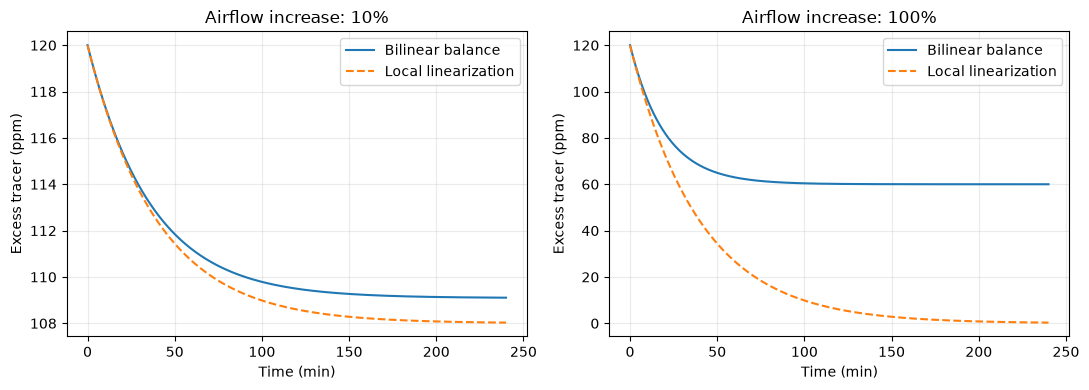

In [3]:
fig, axes=plt.subplots(1,2,figsize=(11,4))
for ax,(fraction,exact,linear) in zip(axes,cases):
    ax.plot(time,exact,label='Bilinear balance'); ax.plot(time,linear,'--',label='Local linearization')
    ax.set(xlabel='Time (min)',ylabel='Excess tracer (ppm)',title=f'Airflow increase: {fraction:.0%}'); ax.legend()
fig.tight_layout()

plt.show()

## Interpret and extend
The doubled-flow experiment deliberately leaves the small-signal regime. Its large error is a limitation of linearization, not a numerical failure.

Change one parameter at a time, predict the direction of its effect from the equations, and rerun all cells. Explain any discrepancy before accepting a revised conclusion.

## References
- [APMonitor Dynamics and Control](https://apmonitor.com/pdc/)
- [Feedback Systems, open textbook](https://fbsbook.org/)
- [Python Control documentation](https://python-control.readthedocs.io/en/0.10.2/)
- [Worked PDF report](report.pdf)